# 02 Aurreprozesamendua eta Pipeline-a

Jatorrizko CSVetatik abiatuta, datu garbiak eta entrenatzeko prest dagoen datu-multzo bat lortuko dugu, eta datu berriekin zuzenean erabil daitekeen scikit-learn Pipeline bat eraikiko dugu. Erabakiak 01 koadernoko EDAtik datoz.

In [1]:
# Liburutegiak
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Gure funtzioak (src karpeta)
sys.path.append("../src")
from karga import datuak_kargatu
from aurreprozesamendua import (ALDAGAI_NUMERIKOAK, ALDAGAI_KATEGORIKOAK,
                                ERREGRESIO_HELBURUA, SAILKAPEN_HELBURUA,
                                balio_ezinezkoak_kendu, outlierrak_zenbatu_iqr, outlierrak_zenbatu_zscore,
                                aldagaiak_sortu, aurreprozesadorea_sortu)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)

## 1. Jatorrizko datuen karga

EDAko funtzio bera erabiltzen dugu, orain lau urteekin (2023-2026). Jatorrizko fitxategiak ez ditugu inoiz aldatzen; emaitza data/prozesatuak karpetan gordetzen da.

In [2]:
df = datuak_kargatu("../data/jatorrizkoak", [2023, 2024, 2025, 2026])
print("Jatorrizko datu-multzoa:", df.shape)
df.head()

Urtea 2023 -> 8760 errenkada
Urtea 2024 -> 8784 errenkada
Urtea 2025 -> 8760 errenkada
Urtea 2026 -> 7584 errenkada
Jatorrizko datu-multzoa: (33874, 18)


,CO,CO_8h,NO,NOX,NO2,PM10,PM25,SO2,haize_norabidea,hezetasuna,tenperatura,haize_abiadura,ICA_NO2,ICA_PM10,ICA_PM25,ICA_SO2,ICA_estazioa,urtea
data,,,,,,,,,,,,,,,,,,
2023-01-01 01:00:00,0.18,0.15,2.0,17.0,15.0,113.0,90.0,8.0,191.0,31.0,19.9,0.48,Oso ona,Ona,Ona,Oso ona,Ona,2023
2023-01-01 02:00:00,0.14,0.15,1.0,10.0,9.0,315.0,288.0,6.0,65.0,33.0,19.8,0.72,Oso ona,Erregularra,Txarra,Oso ona,Txarra,2023
2023-01-01 03:00:00,0.11,0.14,1.0,4.0,3.0,47.0,46.0,6.0,203.0,34.0,20.2,1.17,Oso ona,Erregularra,Txarra,Oso ona,Txarra,2023
2023-01-01 04:00:00,0.31,0.16,1.0,3.0,2.0,33.0,34.0,6.0,220.0,35.0,20.2,0.67,Oso ona,Erregularra,Txarra,Oso ona,Txarra,2023
2023-01-01 05:00:00,0.27,0.17,0.0,5.0,5.0,32.0,33.0,6.0,52.0,38.0,19.3,1.00,Oso ona,Erregularra,Txarra,Oso ona,Txarra,2023


## 2. Garbiketa

### 2.1 Bikoiztutako datak eta falta diren orduak

In [3]:
espero_orduak = pd.date_range(df.index.min(), df.index.max(), freq="h")
print("Bikoiztutako datak:", df.index.duplicated().sum())
print("Falta diren orduak:", len(espero_orduak.difference(df.index)))

Bikoiztutako datak: 0
Falta diren orduak: 0


### 2.2 Balio ezinezkoak

Egon ezin diren balioak nulu bihurtzen ditugu: kontzentrazio edo haize negatiboak, % 0-100 tartetik kanpoko hezetasuna, 0-360º tartetik kanpoko norabidea eta -20 eta 50 ºC artetik kanpoko tenperaturak.

In [4]:
nuluak_lehen = df.isna().sum().sum()
df_garbia = balio_ezinezkoak_kendu(df)
nuluak_gero = df_garbia.isna().sum().sum()
print("Aurkitutako balio ezinezkoak:", nuluak_gero - nuluak_lehen)

Aurkitutako balio ezinezkoak: 0


Ez da halakorik agertzen (sareak datuak balioztatzen ditu argitaratu aurretik), baina urratsa mantentzen dugu datu berrietarako.

### 2.3 Outlierrak

Lehenik IQR metodoa: outlier da Q1 − 1,5·IQR azpitik edo Q3 + 1,5·IQR gainetik dagoena.

In [5]:
berrikusteko_zutabeak = ["CO", "NO", "NO2", "PM10", "PM25", "SO2", "tenperatura", "hezetasuna", "haize_abiadura"]
outlier_taula = outlierrak_zenbatu_iqr(df_garbia, berrikusteko_zutabeak)
outlier_taula

,aldagaia,beheko_muga,goiko_muga,n_outlier,ehunekoa
0,CO,0.07,0.34,1606,4.80
1,NO,-3.50,8.50,4224,12.62
2,NO2,-16.50,51.50,731,2.20
3,PM10,-10.50,49.50,1104,3.87
4,PM25,-8.00,24.00,1173,3.57
5,SO2,-3.00,13.00,1652,5.04
6,tenperatura,0.55,32.15,134,0.45
7,hezetasuna,28.50,112.50,126,0.42
8,haize_abiadura,-0.86,3.54,723,2.41


Gero z-scorearekin alderatzen dugu (batez bestekotik 3 desbideratze baino urrunago).

In [6]:
iqr = outlierrak_zenbatu_iqr(df_garbia, ["NO2", "PM10", "PM25"])
zscore = outlierrak_zenbatu_zscore(df_garbia, ["NO2", "PM10", "PM25"])

outlier_alderaketa = []
for aldagaia in ["NO2", "PM10", "PM25"]:
    seriea = df_garbia[aldagaia]
    iqr_errenkada = iqr[iqr["aldagaia"] == aldagaia].iloc[0]
    iqr_da = seriea > iqr_errenkada["goiko_muga"]
    z_da = ((seriea - seriea.mean()) / seriea.std()).abs() > 3
    outlier_alderaketa.append([aldagaia, iqr_errenkada["goiko_muga"], iqr_da.sum(),
                               zscore[zscore["aldagaia"] == aldagaia].iloc[0]["goiko_muga"], z_da.sum(),
                               (iqr_da & z_da).sum()])

pd.DataFrame(outlier_alderaketa, columns=["aldagaia", "IQR muga", "IQR outlierrak",
                                          "z-score muga", "z-score outlierrak", "biek markatuak"])

,aldagaia,IQR muga,IQR outlierrak,z-score muga,z-score outlierrak,biek markatuak
0,NO2,51.5,731,57.41,388,388
1,PM10,49.5,1104,63.09,375,375
2,PM25,24.0,1173,31.67,449,449


Z-scoreak askoz gutxiago markatzen ditu, banaketa normala suposatzen duelako eta gailurrek berek batez bestekoa eta desbideratzea puzten dituztelako. Datu hauetarako IQR egokiagoa da.

Erabakia: outlierrak mantendu egiten ditugu. Orduen % 2-4 dira, eta episodio errealak dira (baretadun puntako orduak, Urteberriko su artifizialak...). Kenduko bagenitu, ereduak ez luke inoiz episodiorik ikusiko, eta hain zuzen ere horiek detektatu nahi ditugu.

### 2.4 Balio nuluak

Hemen ez ditugu betetzen. Pipeline-ak beteko ditu entrenamenduko datuekin bakarrik, eta 5. atalean erabakiko dugu zein estrategiarekin.

### 2.5 Aldagai erredundanteak

NOX (≈ NO + NO2) eta CO_8h (COaren 8 orduko batez bestekoa) ez ditugu ereduetan erabiliko, ezta kutsatzaile bakoitzaren ICA kategoriak ere.

## 3. Aldagai berriak sortzea

aldagaiak_sortu funtzioak (src/aurreprozesamendua.py) hauek gehitzen ditu:

| Aldagaia | Zergatik |
|---|---|
| ordua, aste_eguna, hilabetea | NO2a puntako orduen, asteko egunaren eta urtaroaren mende dago |
| haize_sektorea | Haizearen norabidea 8 sektoretan diskretizatuta (I, IE, E, HE, H, HM, M, IM) |
| NO2_duela_1h, NO2_duela_24h | Oraingo kutsadura lehengoaren oso mende dago |
| NO2_batez_24h, PM10_batez_24h, PM25_batez_24h | Azken 24 orduetako joera |
| NO2_hurrengoa, PM10_hurrengoa, PM25_hurrengoa | Erregresioaren helburuak (hurrengo ordua) |
| ICA_hurrengoa | Sailkapenaren helburua (hurrengo ordua) |

Sarrerek uneko edo iraganeko informazioa bakarrik erabiltzen dute, eta beti hurrengo ordua iragartzen dugu. Bestela ereduak tranpa egingo luke (data leakage).

In [7]:
df_aldagaiak = aldagaiak_sortu(df_garbia)
df_aldagaiak[["NO2", "NO2_duela_1h", "NO2_duela_24h", "NO2_batez_24h", "NO2_hurrengoa",
              "ICA_estazioa", "ICA_hurrengoa", "ordua", "aste_eguna", "hilabetea", "haize_sektorea"]].head(26)

,NO2,NO2_duela_1h,NO2_duela_24h,NO2_batez_24h,NO2_hurrengoa,ICA_estazioa,ICA_hurrengoa,ordua,aste_eguna,hilabetea,haize_sektorea
data,,,,,,,,,,,
2023-01-01 01:00:00,15.0,NaN,NaN,NaN,9.0,Ona,Txarra,2,6,1,4.0
2023-01-01 02:00:00,9.0,15.0,NaN,NaN,3.0,Txarra,Txarra,3,6,1,1.0
2023-01-01 03:00:00,3.0,9.0,NaN,NaN,2.0,Txarra,Txarra,4,6,1,5.0
2023-01-01 04:00:00,2.0,3.0,NaN,NaN,5.0,Txarra,Txarra,5,6,1,5.0
2023-01-01 05:00:00,5.0,2.0,NaN,NaN,4.0,Txarra,Txarra,6,6,1,1.0
2023-01-01 06:00:00,4.0,5.0,NaN,NaN,3.0,Txarra,Txarra,7,6,1,3.0
2023-01-01 07:00:00,3.0,4.0,NaN,NaN,3.0,Txarra,Txarra,8,6,1,5.0
2023-01-01 08:00:00,3.0,3.0,NaN,NaN,2.0,Txarra,Txarra,9,6,1,3.0
2023-01-01 09:00:00,2.0,3.0,NaN,NaN,1.0,Txarra,Txarra,10,6,1,2.0


In [8]:
# Helburua ezagutzen ez dugun errenkadak kendu (ezin dira entrenatzeko edo ebaluatzeko erabili)
errenkadak_lehen = len(df_aldagaiak)
df_amaierakoa = df_aldagaiak.dropna(subset=[ERREGRESIO_HELBURUA, SAILKAPEN_HELBURUA])
print("Helbururik ez izateagatik kendutako errenkadak:", errenkadak_lehen - len(df_amaierakoa))
print("Azken errenkadak:", len(df_amaierakoa))

Helbururik ez izateagatik kendutako errenkadak: 582
Azken errenkadak: 33292


In [9]:
# Ereduek erabiliko dituzten aldagaiak
ALDAGAIAK = ALDAGAI_NUMERIKOAK + ALDAGAI_KATEGORIKOAK
print("Numerikoak (", len(ALDAGAI_NUMERIKOAK), "):", ALDAGAI_NUMERIKOAK)
print("Kategorikoak (", len(ALDAGAI_KATEGORIKOAK), "):", ALDAGAI_KATEGORIKOAK)

# Sarrerako aldagaietan geratzen diren nuluak (Pipeline-ak beteko ditu)
(df_amaierakoa[ALDAGAIAK].isna().mean() * 100).round(2).sort_values(ascending=False).head(8)

Numerikoak ( 14 ): ['CO', 'NO', 'NO2', 'PM10', 'PM25', 'SO2', 'tenperatura', 'hezetasuna', 'haize_abiadura', 'NO2_duela_1h', 'NO2_duela_24h', 'NO2_batez_24h', 'PM10_batez_24h', 'PM25_batez_24h']
Kategorikoak ( 4 ): ['ordua', 'aste_eguna', 'hilabetea', 'haize_sektorea']


PM10_batez_24h    15.52
PM10              15.47
tenperatura       10.82
haize_abiadura    10.80
haize_sektorea    10.80
hezetasuna        10.80
SO2                2.59
PM25               2.38
dtype: float64

## 4. Entrenamendu / proba banaketa

Denbora-serie bat denez, ezin dugu ausaz banatu (train_test_split): ondoz ondoko orduak oso antzekoak dira eta ereduak etorkizuna ikusiko luke. Urteka banatzen dugu: 2023-2025 entrenatzeko eta 2026 probatzeko.

In [10]:
entrenamendua = df_amaierakoa[df_amaierakoa["urtea"] <= 2025]
proba = df_amaierakoa[df_amaierakoa["urtea"] == 2026]

print("Entrenamendua:", entrenamendua.shape, "| noiztik", entrenamendua.index.min(), "noiz arte", entrenamendua.index.max())
print("Proba:        ", proba.shape, "| noiztik", proba.index.min(), "noiz arte", proba.index.max())

Entrenamendua: (26039, 31) | noiztik 2023-01-01 01:00:00 noiz arte 2026-01-01 00:00:00
Proba:         (7253, 31) | noiztik 2026-01-01 01:00:00 noiz arte 2026-11-12 09:00:00


In [11]:
# ICA klaseen banaketa entrenamenduan eta proban
pd.DataFrame({
    "entrenamendua (%)": (entrenamendua[SAILKAPEN_HELBURUA].value_counts(normalize=True) * 100).round(2),
    "proba (%)": (proba[SAILKAPEN_HELBURUA].value_counts(normalize=True) * 100).round(2),
})

,entrenamendua (%),proba (%)
ICA_hurrengoa,,
Oso ona,57.47,50.45
Ona,35.55,38.78
Erregularra,5.46,9.00
Txarra,1.52,1.76


In [ ]:
#Entrenamendu eta proba banaketak gorde hurrengo moduluetarako
gorde_zutabeak = ALDAGAIAK + [ERREGRESIO_HELBURUA, "PM10_hurrengoa", "PM25_hurrengoa",
                              SAILKAPEN_HELBURUA, "ICA_estazioa", "urtea"]
entrenamendua[gorde_zutabeak].to_csv("../data/prozesatuak/barakaldo_entrenamendua.csv")
proba[gorde_zutabeak].to_csv("../data/prozesatuak/barakaldo_proba.csv")
print("Gordeta: barakaldo_entrenamendua.csv, barakaldo_proba.csv")

Gordeta: barakaldo_entrenamendua.csv, barakaldo_proba.csv


## 5. Eraldaketak

### 5.1 Balio nuluak: zein estrategia?

Apunteetako metodoa erabiltzen dugu: estrategia bakoitzarekin Random Forest bat entrenatzen dugu eta balioztapeneko MAE alderatzen dugu. Entrenamenduaren barruan 2023-2024 entrenatzeko eta 2025 balioztatzeko erabiltzen ditugu (2026a ez dugu ukitzen).

- A · nuluak dituzten errenkadak ezabatu (zutabe guztiek dute nuluren bat, beraz zutabeak ezabatzea ez da aukera)
- B · batez bestekoarekin bete
- C · medianarekin bete
- D · medianarekin bete eta "_was_missing" zutabeak gehitu

In [ ]:
X = entrenamendua[ALDAGAI_NUMERIKOAK]
y = entrenamendua[ERREGRESIO_HELBURUA]
X_train, X_valid = X[entrenamendua["urtea"] <= 2024], X[entrenamendua["urtea"] == 2025]
y_train, y_valid = y[entrenamendua["urtea"] <= 2024], y[entrenamendua["urtea"] == 2025]

def score_dataset(X_train, X_valid, y_train, y_valid):
    model = RandomForestRegressor(n_estimators=100, random_state=0, n_jobs=-1)
    model.fit(X_train, y_train)
    return mean_absolute_error(y_valid, model.predict(X_valid))

cols_with_missing = [c for c in X_train.columns if X_train[c].isna().any()]
emaitzak = {}

# A · nuluak dituzten errenkadak ezabatu
osoak_train = X_train.notna().all(axis=1)
osoak_valid = X_valid.notna().all(axis=1)
emaitzak["A · errenkadak ezabatu"] = score_dataset(X_train[osoak_train], X_valid[osoak_valid],
                                                   y_train[osoak_train], y_valid[osoak_valid])
print("A: entrenamenduko errenkaden", round(100 * (1 - osoak_train.mean()), 1), "% galtzen da")

#B eta C · batez bestekoa eta mediana
for izena, estrategia in [("B · batez bestekoa", "mean"), ("C · mediana", "median")]:
    imp = SimpleImputer(strategy=estrategia)
    X_train_B = pd.DataFrame(imp.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
    X_valid_B = pd.DataFrame(imp.transform(X_valid), columns=X_valid.columns, index=X_valid.index)
    emaitzak[izena] = score_dataset(X_train_B, X_valid_B, y_train, y_valid)

# D · mediana + luzapena
X_train_D, X_valid_D = X_train.copy(), X_valid.copy()
for c in cols_with_missing:
    X_train_D[c + "_was_missing"] = X_train_D[c].isna()
    X_valid_D[c + "_was_missing"] = X_valid_D[c].isna()
imp = SimpleImputer(strategy="median")
X_train_D = pd.DataFrame(imp.fit_transform(X_train_D), columns=X_train_D.columns, index=X_train_D.index)
X_valid_D = pd.DataFrame(imp.transform(X_valid_D), columns=X_valid_D.columns, index=X_valid_D.index)
emaitzak["D · mediana + luzapena"] = score_dataset(X_train_D, X_valid_D, y_train, y_valid)

pd.Series(emaitzak, name="MAE").sort_values().round(3)

A: entrenamenduko errenkaden 32.3 % galtzen da


B · batez bestekoa        4.313
C · mediana               4.317
D · mediana + luzapena    4.323
A · errenkadak ezabatu    4.371
Name: MAE, dtype: float64

Lau estrategiek ia MAE bera ematen dute (4,31 eta 4,37 artean). A da okerrena, eta gainera errenkaden herena galtzen du: denbora errealean ezin genuke iragarri sentsoreren batek huts egiten duen orduetan.

Aldeak % 1 baino txikiagoak direnez, apunteetako irizpidea jarraitzen dugu eta sinpleena aukeratzen dugu: mediana (C). Batez bestekoa baino sendoagoa da gure datu asimetrikoetan.

### 5.2 Estandarizatu edo normalizatu

StandardScaler (batez bestekoa 0, desbideratzea 1) eta MinMaxScaler (0 eta 1 artean) alderatzen ditugu hiru aldagairekin.

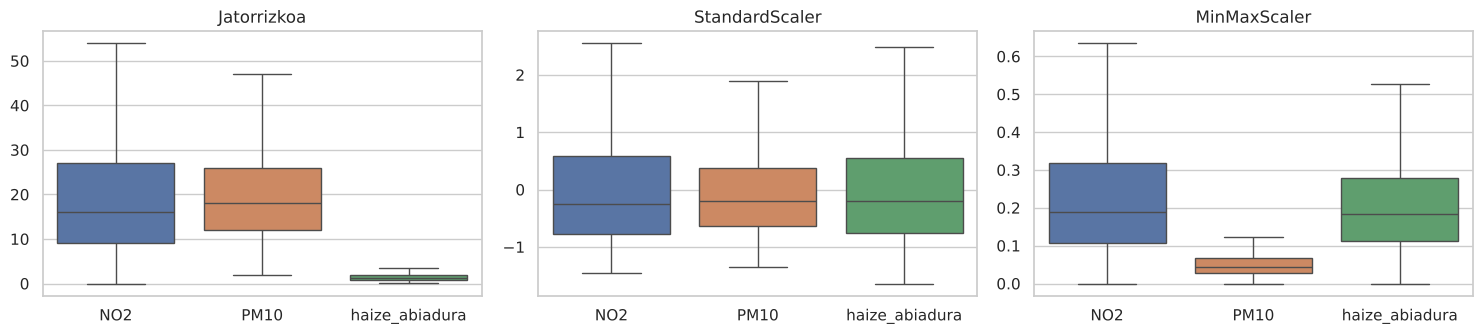

Mediana MinMaxScaler-en ondoren:
NO2               0.188
PM10              0.044
haize_abiadura    0.183
dtype: float64


In [12]:
adibidea = entrenamendua[["NO2", "PM10", "haize_abiadura"]].dropna()

estandarizatua = pd.DataFrame(StandardScaler().fit_transform(adibidea), columns=adibidea.columns)
normalizatua = pd.DataFrame(MinMaxScaler().fit_transform(adibidea), columns=adibidea.columns)

fig, ardatzak = plt.subplots(1, 3, figsize=(15, 3.5))
sns.boxplot(data=adibidea, ax=ardatzak[0], showfliers=False)
ardatzak[0].set_title("Jatorrizkoa")
sns.boxplot(data=estandarizatua, ax=ardatzak[1], showfliers=False)
ardatzak[1].set_title("StandardScaler")
sns.boxplot(data=normalizatua, ax=ardatzak[2], showfliers=False)
ardatzak[2].set_title("MinMaxScaler")
plt.tight_layout()
plt.show()

print("Mediana MinMaxScaler-en ondoren:")
print(normalizatua.median().round(3))

StandardScaler aukeratzen dugu. MinMaxScaler-ekin gailur oso altuek (PM10 364 arte) gainerako balioak 0tik gertu estutzen dituzte; StandardScaler-ek hobeto jasaten ditu.

### 5.3 One-hot kodeketa

ordua, aste_eguna, hilabetea eta haize_sektorea kategoriak dira, ez kantitateak (12. hilabetea ez da 6.aren bikoitza, eta 23:00ak eta 00:00ak gertu daude). One-hot bidez kodetzen ditugu.

### 5.4 Aurreprozesadore osoa

aurreprozesadorea_sortu funtzioak ColumnTransformer bat egiten du:

- Numerikoak: SimpleImputer(mediana) → StandardScaler
- Kategorikoak: SimpleImputer(maizena) → OneHotEncoder

Entrenamenduarekin bakarrik egiten da fit, eta gero entrenamenduari eta probari transform.

In [13]:
aurreprozesadorea = aurreprozesadorea_sortu(ALDAGAI_NUMERIKOAK, ALDAGAI_KATEGORIKOAK)

X_entr = aurreprozesadorea.fit_transform(entrenamendua[ALDAGAIAK])
X_proba = aurreprozesadorea.transform(proba[ALDAGAIAK])

zutabe_izenak = aurreprozesadorea.named_steps["eraldatu"].get_feature_names_out()
print("Zutabeak lehen:", len(ALDAGAIAK), "-> zutabeak gero:", X_entr.shape[1])
print("Nuluak eraldatu ondoren -> entrenamendua:", np.isnan(X_entr).sum(), "| proba:", np.isnan(X_proba).sum())
print()
print("One-hot-ek sortutako zutabeak:")
print([z for z in zutabe_izenak if z.startswith("kategorikoak")])

Zutabeak lehen: 18 -> zutabeak gero: 65
Nuluak eraldatu ondoren -> entrenamendua: 0 | proba: 0

One-hot-ek sortutako zutabeak:
['kategorikoak__ordua_0.0', 'kategorikoak__ordua_1.0', 'kategorikoak__ordua_2.0', 'kategorikoak__ordua_3.0', 'kategorikoak__ordua_4.0', 'kategorikoak__ordua_5.0', 'kategorikoak__ordua_6.0', 'kategorikoak__ordua_7.0', 'kategorikoak__ordua_8.0', 'kategorikoak__ordua_9.0', 'kategorikoak__ordua_10.0', 'kategorikoak__ordua_11.0', 'kategorikoak__ordua_12.0', 'kategorikoak__ordua_13.0', 'kategorikoak__ordua_14.0', 'kategorikoak__ordua_15.0', 'kategorikoak__ordua_16.0', 'kategorikoak__ordua_17.0', 'kategorikoak__ordua_18.0', 'kategorikoak__ordua_19.0', 'kategorikoak__ordua_20.0', 'kategorikoak__ordua_21.0', 'kategorikoak__ordua_22.0', 'kategorikoak__ordua_23.0', 'kategorikoak__aste_eguna_0.0', 'kategorikoak__aste_eguna_1.0', 'kategorikoak__aste_eguna_2.0', 'kategorikoak__aste_eguna_3.0', 'kategorikoak__aste_eguna_4.0', 'kategorikoak__aste_eguna_5.0', 'kategorikoak__ast

## 6. Dimentsio-murrizketa

One-hot-en ondoren zutabe asko ditugu. PCA probatzen dugu, ea zutabeak murriztu ditzakegun eta ereduan zer eragin duen.

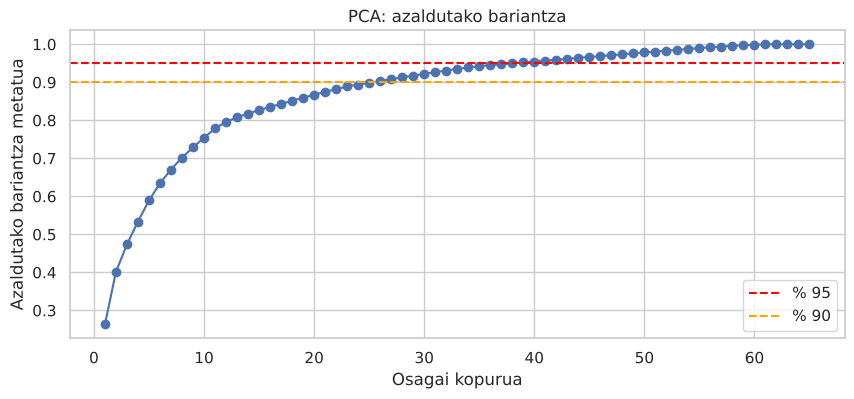

Lehen 3 osagaien bariantza: [0.263 0.138 0.072]
% 90erako osagaiak: 26
% 95erako osagaiak: 39


In [ ]:
#PCA osagai guztiekin, azaldutako bariantza ikusteko
pca = PCA()
pca.fit(X_entr)
bariantza_metatua = np.cumsum(pca.explained_variance_ratio_)

n_90 = np.argmax(bariantza_metatua >= 0.90) + 1
n_95 = np.argmax(bariantza_metatua >= 0.95) + 1

plt.figure(figsize=(10, 4))
plt.plot(range(1, len(bariantza_metatua) + 1), bariantza_metatua, marker="o")
plt.axhline(0.95, color="red", linestyle="--", label="% 95")
plt.axhline(0.90, color="orange", linestyle="--", label="% 90")
plt.xlabel("Osagai kopurua")
plt.ylabel("Azaldutako bariantza metatua")
plt.title("PCA: azaldutako bariantza")
plt.legend()
plt.show()

print("Lehen 3 osagaien bariantza:", pca.explained_variance_ratio_[:3].round(3))
print("% 90erako osagaiak:", n_90)
print("% 95erako osagaiak:", n_95)

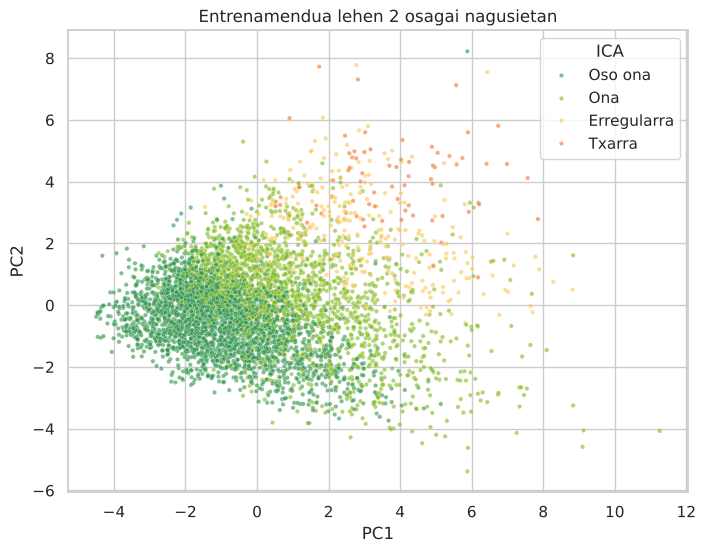

In [14]:
# Entrenamenduko datuak lehen bi osagaietan proiektatuta, ICA kategoriaren arabera koloreztatuta
proiekzioa = pca.transform(X_entr)[:, :2]
grafikoa = pd.DataFrame({"PC1": proiekzioa[:, 0], "PC2": proiekzioa[:, 1],
                         "ICA": entrenamendua[SAILKAPEN_HELBURUA].values})
lagina = grafikoa.sample(5000, random_state=42)

plt.figure(figsize=(8, 6))
sns.scatterplot(data=lagina, x="PC1", y="PC2", hue="ICA", s=10, alpha=0.6,
                hue_order=["Oso ona", "Ona", "Erregularra", "Txarra"],
                palette=["#2b9348", "#80b918", "#f9c74f", "#f3722c"])
plt.title("Entrenamendua lehen 2 osagai nagusietan")
plt.show()

In [ ]:
#PCAren eragina eredu sinple batean (hurrengo orduko NO2aren erregresio lineala)
y_entr = entrenamendua[ERREGRESIO_HELBURUA]
y_proba = proba[ERREGRESIO_HELBURUA]

emaitzak = []
for pca_erabili in [False, True]:
    eredua = Pipeline([
        ("aurreprozesamendua", aurreprozesadorea_sortu(ALDAGAI_NUMERIKOAK, ALDAGAI_KATEGORIKOAK, pca_erabili=pca_erabili)),
        ("eredua", LinearRegression()),
    ])
    hasiera = time.time()
    eredua.fit(entrenamendua[ALDAGAIAK], y_entr)
    denbora = time.time() - hasiera
    iragarpena = eredua.predict(proba[ALDAGAIAK])

    if pca_erabili:
        n_zutabe = eredua.named_steps["aurreprozesamendua"].named_steps["pca"].n_components_
    else:
        n_zutabe = X_entr.shape[1]

    emaitzak.append(["PCArekin (% 95)" if pca_erabili else "PCArik gabe", n_zutabe,
                     mean_absolute_error(y_proba, iragarpena),
                     np.sqrt(mean_squared_error(y_proba, iragarpena)),
                     r2_score(y_proba, iragarpena), denbora])

pd.DataFrame(emaitzak, columns=["proba", "zutabeak", "MAE", "RMSE", "R2", "denbora_s"]).round(3)

,proba,zutabeak,MAE,RMSE,R2,denbora_s
0,PCArik gabe,65,4.263,6.314,0.766,0.608
1,PCArekin (% 95),39,4.294,6.421,0.758,0.084


#### Ondorioak

- Bariantzaren % 95 mantentzeko 65 zutabeetatik 39 behar dira (26, % 90erako).
- Bi osagairekin ICA klaseak ez dira ondo bereizten.
- PCArekin erregresio lineala apur bat okertzen da (MAE 4,26tik 4,29ra) eta entrenamendua ia ez da azkartzen (0,35 s).

Beraz, azken Pipeline-ak ez du PCA erabiltzen. Aukera gisa geratzen da (pca_erabili=True).

## 7. Pipeline osoa (aurreprozesamendua + eredua)

Aurreprozesamendua eta erregresio lineal bat Pipeline bakar batean elkartzen ditugu, dena ondo dabilela egiaztatzeko. Iraunkortasunarekin alderatzen dugu (hurrengo orduko NO2a oraingoa izango dela esatea).

In [15]:
pipeline_no2 = Pipeline([
    ("aurreprozesamendua", aurreprozesadorea_sortu(ALDAGAI_NUMERIKOAK, ALDAGAI_KATEGORIKOAK)),
    ("eredua", LinearRegression()),
])

# 2023-2025ekin entrenatu
pipeline_no2.fit(entrenamendua[ALDAGAIAK], y_entr)

# 2026rekin ebaluatu
iragarpena = pipeline_no2.predict(proba[ALDAGAIAK])
iraunkortasuna = proba["NO2"].fillna(entrenamendua["NO2"].median())

taula = pd.DataFrame({
    "MAE": [mean_absolute_error(y_proba, iraunkortasuna), mean_absolute_error(y_proba, iragarpena)],
    "RMSE": [np.sqrt(mean_squared_error(y_proba, iraunkortasuna)), np.sqrt(mean_squared_error(y_proba, iragarpena))],
    "R2": [r2_score(y_proba, iraunkortasuna), r2_score(y_proba, iragarpena)],
}, index=["Iraunkortasuna (uneko NO2a)", "Pipeline + erregresio lineala"])
taula.round(3)

,MAE,RMSE,R2
Iraunkortasuna (uneko NO2a),4.554,7.010,0.712
Pipeline + erregresio lineala,4.263,6.314,0.766


Pipeline-ak prozesatu gabeko zutabeak jasotzen ditu (nuluekin, eskalatu gabe) eta iragarpena itzultzen du. Erregresio linealak iraunkortasuna hobetzen du, gutxigatik bada ere; 5072 moduluan eredu gehiago probatuko ditugu aurreprozesamendu hau bera erabiliz.

Hiperparametroak ere Pipeline osoaren gainean doitzen dira, GridSearchCV-rekin. Parametroak urratsaren izena eta bi azpimarra jarrita adierazten dira, eta balioztapen-zatiketa bakoitzean aurreprozesamendua ere berriz doitzen da (horrela ez dago datu-ihesik). Adibidez, 03 koadernoan Ridgerako:

```python
ridge_eredua = Pipeline([("aurreprozesamendua", aurreprozesadorea_sortu(...)), ("eredua", Ridge())])
GridSearchCV(ridge_eredua, {"eredua__alpha": [0.01, 0.1, 1, 10, 100, 1000, 10000]}, cv=TimeSeriesSplit(5))
```

Gauza bera egiten da Lassorekin (03) eta KNN, zuhaitza, Naive Bayes eta Random Forestarekin (04).

## 8. Pipeline-a gorde (joblib)

In [16]:
joblib.dump(aurreprozesadorea, "../ereduak/aurreprozesadorea.joblib")
joblib.dump(pipeline_no2, "../ereduak/pipeline_erregresioa_NO2.joblib")

# Pipeline-ak espero dituen aldagaien zerrenda ere gordetzen dugu
joblib.dump(ALDAGAIAK, "../ereduak/sarrera_aldagaiak.joblib")
print("ereduak/ karpetan gordeta")

ereduak/ karpetan gordeta


## 9. Proba datu berriekin

Datu berriak iristen direla simulatzen dugu: 2026ko azken 3 egunak jatorrizko CSVtik irakurri, garbiketa eta aldagaiak sortzeko funtzio berberak aplikatu eta joblib-etik kargatutako Pipeline-ari pasatu. 3 egun hartzen ditugu, 24 orduko batez bestekoek historia behar dutelako.

In [ ]:
# 1) Gordetako pipeline-a kargatu (beste programa bat izango balitz bezala)
kargatutako_pipeline = joblib.load("../ereduak/pipeline_erregresioa_NO2.joblib")
sarrera_aldagaiak = joblib.load("../ereduak/sarrera_aldagaiak.joblib")

# 2) Datu berriak iristen dira jatorrizko CSV formatuan
berriak = datuak_kargatu("../data/jatorrizkoak", [2026])
berriak = berriak.iloc[-72:]
print("Datu berriak:", berriak.shape)

# 3) Entrenamenduko prozesu bera
berriak = balio_ezinezkoak_kendu(berriak)
berriak = aldagaiak_sortu(berriak)

# 4)Hurrengo orduko NO2aren iragarpena
berriak["NO2_iragarria"] = kargatutako_pipeline.predict(berriak[sarrera_aldagaiak])
berriak[["NO2", "NO2_hurrengoa", "NO2_iragarria"]].tail(10).round(1)

Urtea 2026 -> 7584 errenkada
Datu berriak: (72, 18)


,NO2,NO2_hurrengoa,NO2_iragarria
data,,,
2026-11-12 01:00:00,14.0,17.0,14.6
2026-11-12 02:00:00,17.0,19.0,16.8
2026-11-12 03:00:00,19.0,22.0,19.4
2026-11-12 04:00:00,22.0,10.0,24.0
2026-11-12 05:00:00,10.0,23.0,14.7
2026-11-12 06:00:00,23.0,38.0,30.1
2026-11-12 07:00:00,38.0,27.0,40.1
2026-11-12 08:00:00,27.0,21.0,24.4
2026-11-12 09:00:00,21.0,11.0,17.9


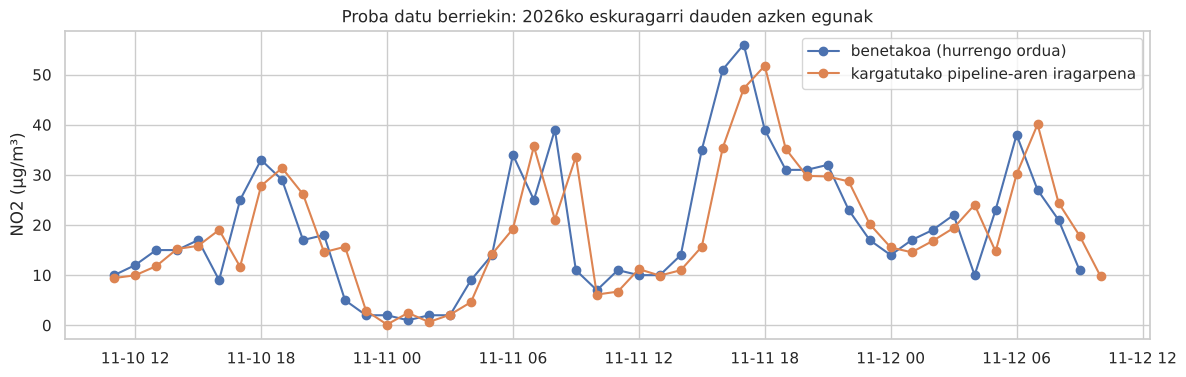

MAE datu berri hauetan: 6.01 µg/m³


In [17]:
azkenak = berriak.iloc[24:]
plt.figure(figsize=(14, 4))
plt.plot(azkenak.index, azkenak["NO2_hurrengoa"], marker="o", label="benetakoa (hurrengo ordua)")
plt.plot(azkenak.index, azkenak["NO2_iragarria"], marker="o", label="kargatutako pipeline-aren iragarpena")
plt.title("Proba datu berriekin: 2026ko eskuragarri dauden azken egunak")
plt.ylabel("NO2 (µg/m³)")
plt.legend()
plt.show()

print("MAE datu berri hauetan:",
      round(mean_absolute_error(azkenak["NO2_hurrengoa"].dropna(),
                                azkenak.loc[azkenak["NO2_hurrengoa"].notna(), "NO2_iragarria"]), 2), "µg/m³")

Gordetako Pipeline-ak datu berriekin funtzionatzen du, jatorrizko CSV formatutik abiatuta. Azken orduak ez du benetako hurrengo baliorik (etorkizuna da), baina iragarpena badu: hori da sistemak denbora errealean behar duena.

## 10. Laburpena

| # | Urratsa | Non |
|---|---|---|
| 1 | CSVak irakurri, datak konpondu eta urteak elkartu | karga.py |
| 2 | Balio ezinezkoak nulu bihurtu (ez da bat ere agertu) | balio_ezinezkoak_kendu |
| 3 | Outlierrak IQR eta z-scorearekin aztertu eta mantendu | outlierrak_zenbatu_iqr / _zscore |
| 4 | Aldagai berriak: egutegia, haize-sektorea, historia eta helburuak | aldagaiak_sortu |
| 5 | Helbururik gabeko errenkadak kendu eta urteka banatu (2023-2025 / 2026) | koadernoa |
| 6 | Nuluak medianarekin bete (apunteetako A-D alderaketaren ondoren) | Pipeline |
| 7 | StandardScaler numerikoei eta one-hot kategoriei | Pipeline |
| 8 | PCA probatu eta baztertu | koadernoa |
| 9 | Hiperparametroak Pipeline osoaren gainean doitu (GridSearchCV) | 03 eta 04 koadernoak |
| 10 | Pipeline-a joblib-ekin gorde eta datu berriekin probatu | ereduak/ |

Sortutako fitxategiak: data/prozesatuak karpetako CSVak (entrenamendua eta proba) eta ereduak karpetako aurreprozesadorea.joblib, pipeline_erregresioa_NO2.joblib eta sarrera_aldagaiak.joblib.